In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import optuna
from sklearn.base import clone
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split

In [71]:
#Importing Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

In [72]:
df = pd.read_csv(r"C:\Users\ore\Desktop\dev\Projects\Customer Churn Project\data\Customer-Churn-Records.csv")
df.drop(columns = ["RowNumber", "CustomerId", "Surname"], inplace = True)
df.head(10)

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425
5,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1,1,5,DIAMOND,484
6,822,France,Male,50,7,0.00,2,1,1,10062.80,0,0,2,SILVER,206
7,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1,1,2,DIAMOND,282
8,501,France,Male,44,4,142051.07,2,0,1,74940.50,0,0,3,GOLD,251
9,684,France,Male,27,2,134603.88,1,1,1,71725.73,0,0,3,GOLD,342


In [73]:
df = df.rename(columns = {'Satisfaction Score' : 'SatisfactionScore',
                          'Card Type' : 'CardType',
                          'Point Earned' : 'PointEarned'})

In [74]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CreditScore        10000 non-null  int64  
 1   Geography          10000 non-null  str    
 2   Gender             10000 non-null  str    
 3   Age                10000 non-null  int64  
 4   Tenure             10000 non-null  int64  
 5   Balance            10000 non-null  float64
 6   NumOfProducts      10000 non-null  int64  
 7   HasCrCard          10000 non-null  int64  
 8   IsActiveMember     10000 non-null  int64  
 9   EstimatedSalary    10000 non-null  float64
 10  Exited             10000 non-null  int64  
 11  Complain           10000 non-null  int64  
 12  SatisfactionScore  10000 non-null  int64  
 13  CardType           10000 non-null  str    
 14  PointEarned        10000 non-null  int64  
dtypes: float64(2), int64(10), str(3)
memory usage: 1.3 MB


In [75]:
df = df.rename(columns = {"Exited": "Churned"})

In [76]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Churned,Complain,SatisfactionScore,CardType,PointEarned
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [77]:
df['Churned'].value_counts()

Churned
0    7962
1    2038
Name: count, dtype: int64

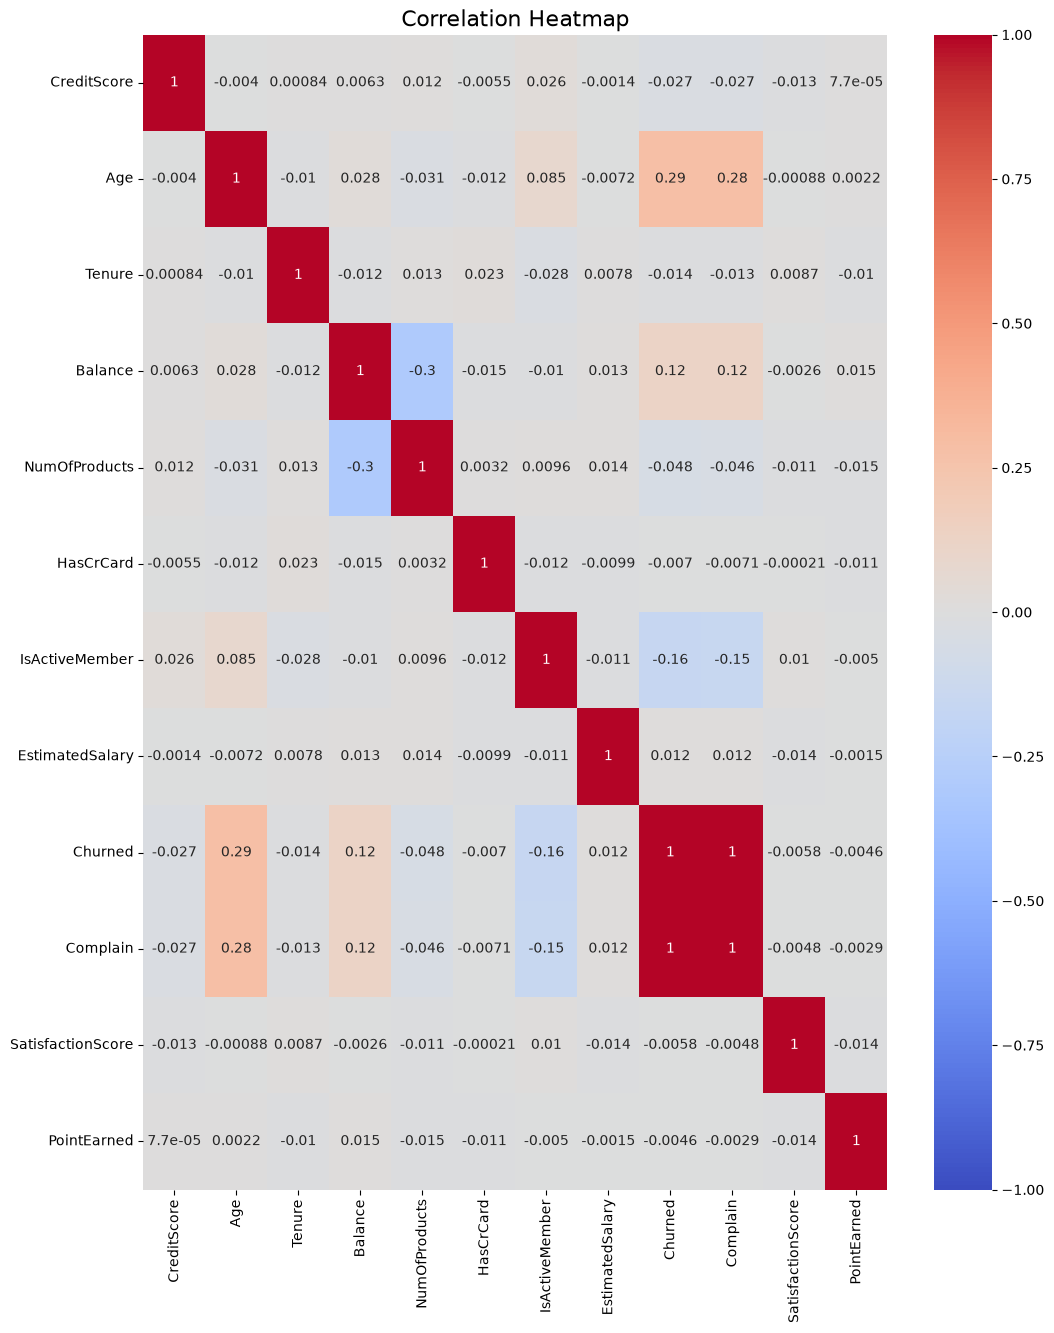

In [78]:
df_corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 15))
sns.heatmap(df_corr, annot=True, cmap='coolwarm', vmin = -1, vmax = 1)
plt.title('Correlation Heatmap', fontsize=16)
plt.show()

In [79]:
df[(df['Churned'] == 1) & (df['Complain'] == 0)].head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Churned,Complain,SatisfactionScore,CardType,PointEarned
16,653,Germany,Male,58,1,132602.88,1,1,0,5097.67,1,0,2,SILVER,163
138,584,Spain,Female,48,2,213146.20,1,1,0,75161.25,1,0,4,DIAMOND,814
144,691,France,Female,31,5,40915.55,1,1,0,126213.84,1,0,2,SILVER,402
9978,774,France,Male,40,9,93017.47,2,1,0,191608.97,1,0,1,GOLD,354


Complain heavily infuences customer churn

data leakage?

In [80]:
df.drop(columns = ["Complain"], inplace = True)
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Churned,SatisfactionScore,CardType,PointEarned
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,2,DIAMOND,464
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,3,DIAMOND,456
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,3,DIAMOND,377
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,5,GOLD,350
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,5,GOLD,425


In [81]:
df["Geography"].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [82]:
X = df.drop(columns = ["Churned"])
y = df["Churned"]

In [83]:
#Define Preprocessing Steps
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

#Id Column Types
numerical_cols = X.select_dtypes(exclude='object').columns
categorical_cols = X.select_dtypes(include='object').columns

#Define Transformers
numerical_trans = Pipeline(steps= [
    ("impute", SimpleImputer(strategy = "median")),
    ('scaler', StandardScaler())
])

categorical_trans = Pipeline(steps= [
    ("impute", SimpleImputer(strategy = "most_frequent")),
    ('onehot', OneHotEncoder(handle_unknown= 'ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_trans, numerical_cols),
        ('cat', categorical_trans, categorical_cols)
    ])

C:\Users\ore\AppData\Local\Temp\ipykernel_12300\3739827391.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include='object').columns


In [84]:
#Split the data into training, validation, and test sets
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.11, random_state=42, stratify=y_train_full)

Baselines

In [85]:
#Define Function to Test Baselines
def evaluate(model):
    #Create a pipeline with the preprocessor and the model
    baseline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', model(random_state=42))])
    
    #Fit the pipeline on the training data
    baseline.fit(X_train, y_train)
    
    #Validate
    y_pred = baseline.predict(X_val)
    validation_accuracy = accuracy_score(y_val, y_pred)
    print(f"Validation Accuracy: {validation_accuracy}")
    print(f"\nClassification Report: \n {classification_report(y_val,y_pred)}")
    ConfusionMatrixDisplay.from_estimator(baseline, X_val, y_val)

Validation Accuracy: 0.8121212121212121

Classification Report: 
               precision    recall  f1-score   support

           0       0.83      0.96      0.89       788
           1       0.61      0.22      0.33       202

    accuracy                           0.81       990
   macro avg       0.72      0.59      0.61       990
weighted avg       0.78      0.81      0.78       990



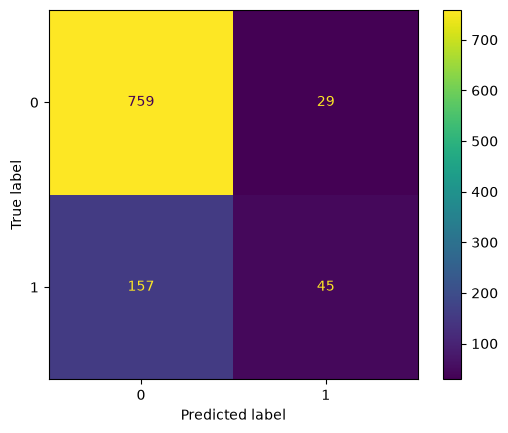

In [86]:
evaluate(LogisticRegression)

Validation Accuracy: 0.8717171717171717

Classification Report: 
               precision    recall  f1-score   support

           0       0.88      0.98      0.92       788
           1       0.84      0.46      0.59       202

    accuracy                           0.87       990
   macro avg       0.86      0.72      0.76       990
weighted avg       0.87      0.87      0.86       990



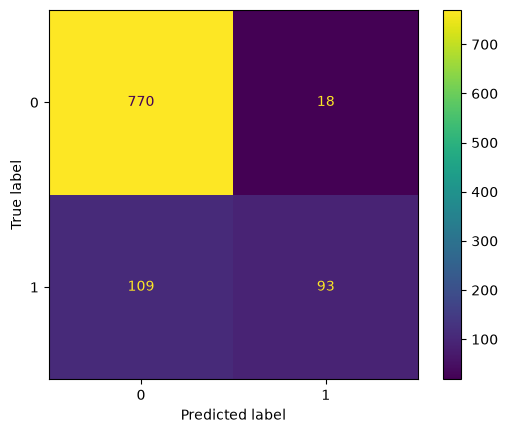

In [87]:
evaluate(RandomForestClassifier)

Validation Accuracy: 0.8545454545454545

Classification Report: 
               precision    recall  f1-score   support

           0       0.87      0.95      0.91       788
           1       0.72      0.47      0.57       202

    accuracy                           0.85       990
   macro avg       0.80      0.71      0.74       990
weighted avg       0.84      0.85      0.84       990



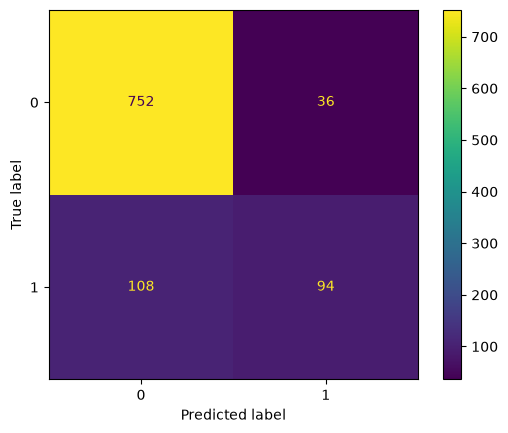

In [88]:
evaluate(XGBClassifier)

Hyperparameter Tuning

In [89]:
#Hyperparameter Tuning Random Forest Model using Optuna
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective(trial):
    params = {
        'classifier__max_depth': trial.suggest_categorical('max_depth', [None, 5, 10, 20]),
        'classifier__min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'classifier__min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 300),
        'classifier__max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        'classifier__class_weight': trial.suggest_categorical(
            'class_weight', [None, 'balanced', 'balanced_subsample']
        ),
    }

    model = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', RandomForestClassifier(random_state=42))])
    model.set_params(**params)

    scores = cross_val_score(
        model, X_train, y_train,
        cv=cv,
        scoring='recall',
        n_jobs=1,
    )
    return scores.mean()

study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42),
)
study.optimize(objective, n_trials=50, show_progress_bar=False)

print("Best score:", study.best_value)
print("Best Parameters:", study.best_params)

[I 2026-11-13 12:46:19,237] A new study created in memory with name: no-name-6b970e73-0b49-41be-b23f-c86f75356a40
[I 2026-11-13 12:46:24,114] Trial 0 finished with value: 0.7181478771505224 and parameters: {'max_depth': 5, 'min_samples_split': 4, 'min_samples_leaf': 47, 'max_features': 'log2', 'class_weight': 'balanced_subsample'}. Best is trial 0 with value: 0.7181478771505224.
[I 2026-11-13 12:46:32,402] Trial 1 finished with value: 0.6973396371550251 and parameters: {'max_depth': None, 'min_samples_split': 7, 'min_samples_leaf': 158, 'max_features': None, 'class_weight': 'balanced_subsample'}. Best is trial 0 with value: 0.7181478771505224.
[I 2026-11-13 12:46:36,064] Trial 2 finished with value: 0.723048348061012 and parameters: {'max_depth': 5, 'min_samples_split': 13, 'min_samples_leaf': 14, 'max_features': 'sqrt', 'class_weight': 'balanced'}. Best is trial 2 with value: 0.723048348061012.
[I 2026-11-13 12:46:38,848] Trial 3 finished with value: 0.10354589970169417 and parameters

Best score: 0.7340931689836963
Best Parameters: {'max_depth': 5, 'min_samples_split': 20, 'min_samples_leaf': 159, 'max_features': 'sqrt', 'class_weight': 'balanced'}


Validation Accuracy: 0.7595959595959596

Classification Report: 
               precision    recall  f1-score   support

           0       0.91      0.78      0.84       788
           1       0.44      0.70      0.54       202

    accuracy                           0.76       990
   macro avg       0.68      0.74      0.69       990
weighted avg       0.81      0.76      0.78       990



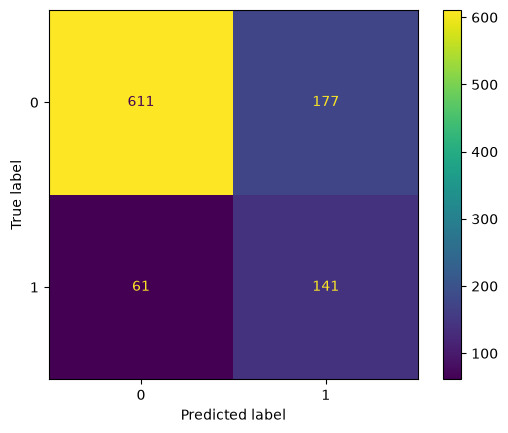

In [90]:
best_params = {f'classifier__{k}': v for k, v in study.best_params.items()}
best_model = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', RandomForestClassifier(random_state=42))])
best_model.set_params(**best_params)
best_model.fit(X_train, y_train)

#Validation
y_pred = best_model.predict(X_val)
validation_accuracy = accuracy_score(y_val, y_pred)
print(f"Validation Accuracy: {validation_accuracy}")
print(f"\nClassification Report: \n {classification_report(y_val,y_pred)}")
ConfusionMatrixDisplay.from_estimator(best_model, X_val, y_val)

In [91]:
#Hyperparameter Tuning Random Forest Model using Optuna with F1 Score
def objective(trial):
    params = {
        'classifier__max_depth': trial.suggest_categorical('max_depth', [None, 5, 10, 20]),
        'classifier__min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'classifier__min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 300),
        'classifier__max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        'classifier__class_weight': trial.suggest_categorical(
            'class_weight', [None, 'balanced', 'balanced_subsample']
        ),
    }

    model = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', RandomForestClassifier(random_state=42))])
    model.set_params(**params)

    scores = cross_val_score(
        model, X_train, y_train,
        cv=cv,
        scoring='f1',
        n_jobs=1,
    )
    return scores.mean()

study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42),
)
study.optimize(objective, n_trials=50, show_progress_bar=False)

best_params = {f'classifier__{k}': v for k, v in study.best_params.items()}
best_model_f1 = Pipeline(steps=[('preprocessor', preprocessor),
                                  ('classifier', RandomForestClassifier(random_state=42))])
best_model_f1.set_params(**best_params)
print("Best score:", study.best_value)
print("Best Parameters:", study.best_params)

[I 2026-11-13 12:49:51,033] A new study created in memory with name: no-name-c8eb4a85-68c2-43f4-a69c-e8fded591dd9
[I 2026-11-13 12:49:54,560] Trial 0 finished with value: 0.5734339588841627 and parameters: {'max_depth': 5, 'min_samples_split': 4, 'min_samples_leaf': 47, 'max_features': 'log2', 'class_weight': 'balanced_subsample'}. Best is trial 0 with value: 0.5734339588841627.
[I 2026-11-13 12:50:02,223] Trial 1 finished with value: 0.5310436745923492 and parameters: {'max_depth': None, 'min_samples_split': 7, 'min_samples_leaf': 158, 'max_features': None, 'class_weight': 'balanced_subsample'}. Best is trial 0 with value: 0.5734339588841627.
[I 2026-11-13 12:50:05,603] Trial 2 finished with value: 0.5808277303968746 and parameters: {'max_depth': 5, 'min_samples_split': 13, 'min_samples_leaf': 14, 'max_features': 'sqrt', 'class_weight': 'balanced'}. Best is trial 2 with value: 0.5808277303968746.
[I 2026-11-13 12:50:09,048] Trial 3 finished with value: 0.18435725841112607 and paramete

Best score: 0.6218953809913597
Best Parameters: {'max_depth': None, 'min_samples_split': 8, 'min_samples_leaf': 3, 'max_features': 'log2', 'class_weight': 'balanced'}


Validation Accuracy: 0.8373737373737373

Classification Report: 
               precision    recall  f1-score   support

           0       0.90      0.89      0.90       788
           1       0.60      0.63      0.61       202

    accuracy                           0.84       990
   macro avg       0.75      0.76      0.76       990
weighted avg       0.84      0.84      0.84       990



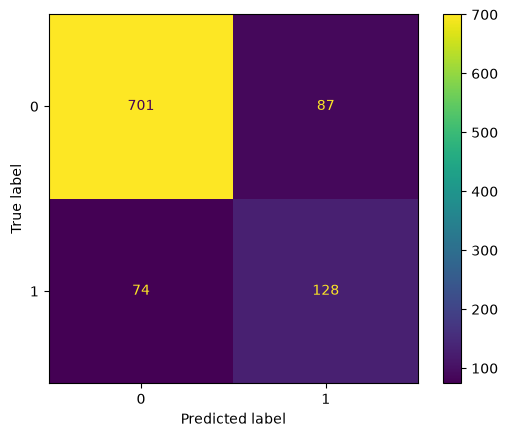

In [92]:
best_model_f1.fit(X_train, y_train)

#Validation
y_pred = best_model_f1.predict(X_val)
validation_accuracy = accuracy_score(y_val, y_pred)
print(f"Validation Accuracy: {validation_accuracy}")
print(f"\nClassification Report: \n {classification_report(y_val,y_pred)}")
ConfusionMatrixDisplay.from_estimator(best_model_f1, X_val, y_val) 

Test Accuracy: 0.821

Classification Report: 
               precision    recall  f1-score   support

           0       0.91      0.86      0.88       796
           1       0.55      0.67      0.60       204

    accuracy                           0.82      1000
   macro avg       0.73      0.77      0.74      1000
weighted avg       0.84      0.82      0.83      1000



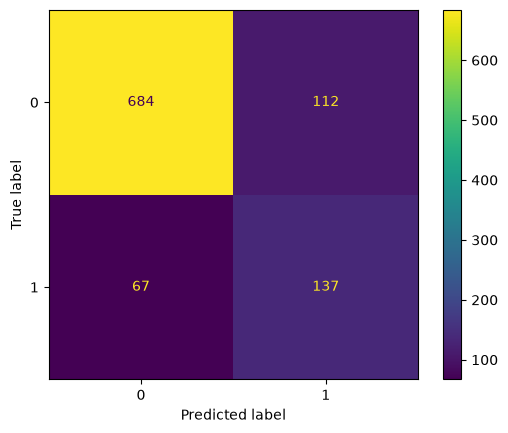

In [93]:
#Building a final model using the best hyperparameters from the F1 score optimization and evaluating it on the test set.
best_model_f1.fit(X_train_full, y_train_full)

#Test Set
y_pred = best_model_f1.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {test_accuracy}")
print(f"\nClassification Report: \n {classification_report(y_test,y_pred)}")
ConfusionMatrixDisplay.from_estimator(best_model_f1, X_test, y_test)

In [94]:
import joblib
joblib.dump(best_model_f1, 'best_model_f1.pkl')

['best_model_f1.pkl']